# 03 — Análise exploratória (Fase 3)

Cada gráfico responde a uma pergunta ligada ao projeto: o tamanho do viés de sobrevivência, o comportamento do alvo ou uma das hipóteses H1–H4.

Regras:
- **Correlações e comparações** entre explicativas e alvo usam **só o treino** (t = 2010–2018). Assim a validação e o teste continuam "não vistos" quando a modelagem começar.
- **Contagens descritivas** (painel, eventos, faltantes) usam a base toda.
- Os gráficos seguem a identidade visual dos slides (`src/style.py`) e são exportados em `figures/` (PNG 16:9, 200 dpi).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, dados, eda, style

style.aplicar()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: style.num_br(x, 3))

ea = pd.read_parquet(cfg.DATA_PROCESSED / 'base_empresa_ano.parquet')
risco = ea[ea['em_risco']]
treino = risco[risco['split'] == 'treino']
cad = dados.carregar_cad_cvm()
cad1 = dados.cad_por_cnpj(cad)
em_bolsa = eda.cnpjs_com_acoes_em_bolsa()
print('Base:', ea.shape, '| amostra em risco:', len(risco), '| treino:', len(treino))

Base: (3633, 58) | amostra em risco: 1708 | treino: 957


## 1. Viés de sobrevivência

A Fase 1 mostrou que o *Screening* do Economatica trouxe praticamente só as empresas **listadas hoje**. Esta seção mede o tamanho do problema.

### 1a. Quantas companhias a base cobre em cada ano?

Comparamos o nº de empresas na base com o nº de companhias **ativas na CVM** em cada ano, excluindo as financeiras pelo setor da CVM. Uma companhia está ativa no ano quando `DT_REG ≤ 31/12` e o registro não foi cancelado até 31/12.

O cadastro da CVM também inclui companhias abertas **sem ações em bolsa**, como emissoras só de debêntures e concessionárias, que nunca estariam num *Screening* de ações. Por isso mostramos uma segunda referência, mais justa: as ativas que tiveram **ações negociadas em bolsa** em algum FCA de 2010 a 2026. A cobertura é calculada sobre essa segunda referência, cruzando por CNPJ.

In [2]:
cob = eda.cobertura_por_ano(ea, cad, em_bolsa)
cob.style.format({c: lambda x: style.pct_br(x, 1) for c in ['cobertura CVM', 'cobertura bolsa']})

,base,base (já registradas),CVM ativas,CVM ativas c/ ações em bolsa,cobertura CVM,cobertura bolsa
ano,,,,,,
2010,172,164,542,348,"30,3%","46,6%"
2011,174,169,530,350,"31,9%","47,7%"
2012,179,171,520,342,"32,7%","49,1%"
2013,181,177,531,345,"33,3%","50,7%"
2014,188,181,515,336,"35,0%","53,0%"
2015,195,185,516,334,"35,7%","54,5%"
2016,206,191,497,325,"37,8%","57,2%"
2017,232,196,498,329,"38,8%","58,1%"
2018,243,200,494,326,"39,9%","59,8%"


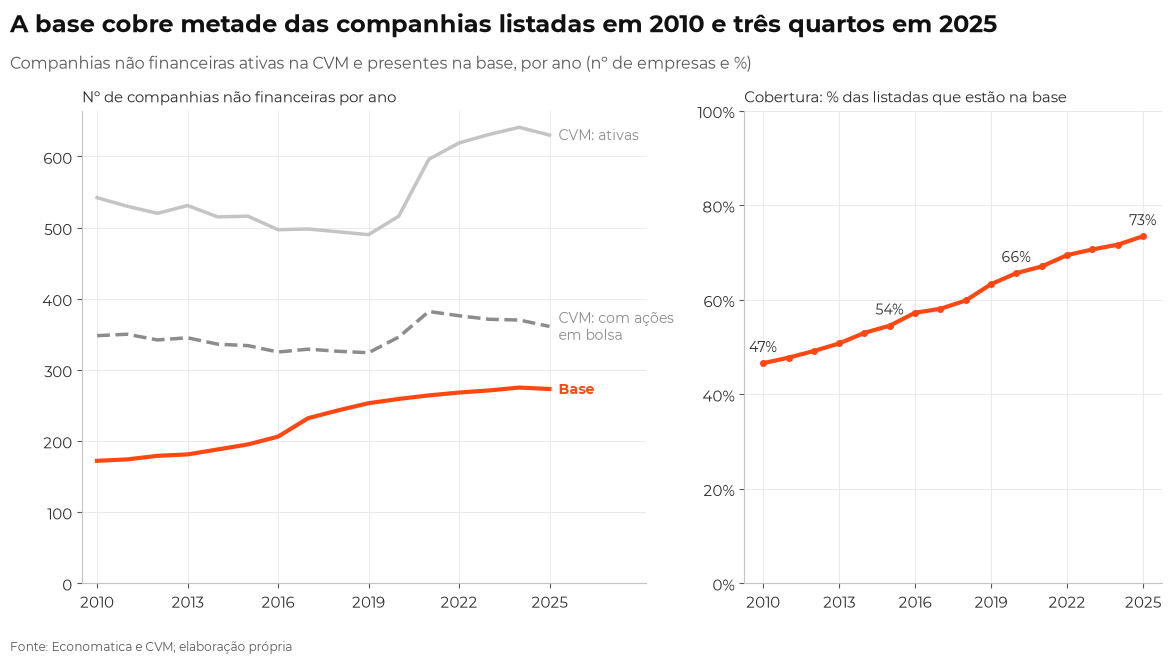

In [3]:
fig = eda.fig_cobertura(cob)
style.titulos(fig, 'A base cobre metade das companhias listadas em 2010 e três quartos em 2025',
              'Companhias não financeiras ativas na CVM e presentes na base, por ano (nº de empresas e %)')
style.salvar(fig, 'fig01_cobertura_base_cvm')
plt.show()

**Leitura.** O nº de companhias com ações em bolsa na CVM fica estável, entre 360 e 390, enquanto a base cresce de 172 para 273 empresas. A cobertura sobe de **47% em 2010 para 73% em 2025**. A explicação é mecânica: uma empresa que estava listada em 2010 e fechou o capital (por falência, incorporação ou OPA) não está na base, porque não passa pelo filtro "listada hoje". Quanto mais para trás no tempo, mais empresas desse tipo existem, e menor a cobertura. Em relação a todas as companhias ativas na CVM (incluindo as sem ações), a cobertura vai de 30% a 43%.

### 1b. Canceladas no período que não estão na base

Usamos o registro mais recente de cada CNPJ. Marcamos com **sinal de distress** os casos com "recuperação judicial", "falida", "falência" ou "liquidação" no nome ou no motivo, ou com cancelamento **de ofício**. O cancelamento de ofício acontece quando a CVM cancela o registro, em geral porque a empresa parou de entregar demonstrações, que é um sintoma típico de crise.

In [4]:
canc = eda.canceladas_fora_da_base(ea, cad1, em_bolsa)
canc.to_csv(cfg.DATA_PROCESSED / 'canceladas_fora_da_base.csv', index=False, encoding='utf-8-sig')
print('Canceladas (não financeiras, 2010–2026) fora da base:', len(canc))
print('  tinham ações em bolsa:', int(canc['tinha_acoes_em_bolsa'].sum()))
print('  com sinal de distress:', int(canc['sinal_distress'].sum()))
print('  as duas coisas:', int((canc['tinha_acoes_em_bolsa'] & canc['sinal_distress']).sum()))
display(canc['MOTIVO_CANCEL'].value_counts().to_frame('companhias'))

Canceladas (não financeiras, 2010–2026) fora da base: 469
  tinham ações em bolsa: 160
  com sinal de distress: 143
  as duas coisas: 31


,companhias
MOTIVO_CANCEL,
CANCELAMENTO VOLUNTÁRIO,282
CANCELAMENTO DE OFÍCIO,128
ELISÃO POR INCORPORAÇÃO,48
ELISÃO POR EXTINÇÃO DA CIA,6
CANCELAMENTO A PEDIDO (Cia Incentivada),3
ELISÃO POR LIQUIDAÇÃO,1
LIQUIDAÇÃO EXTRAJUDICIAL,1


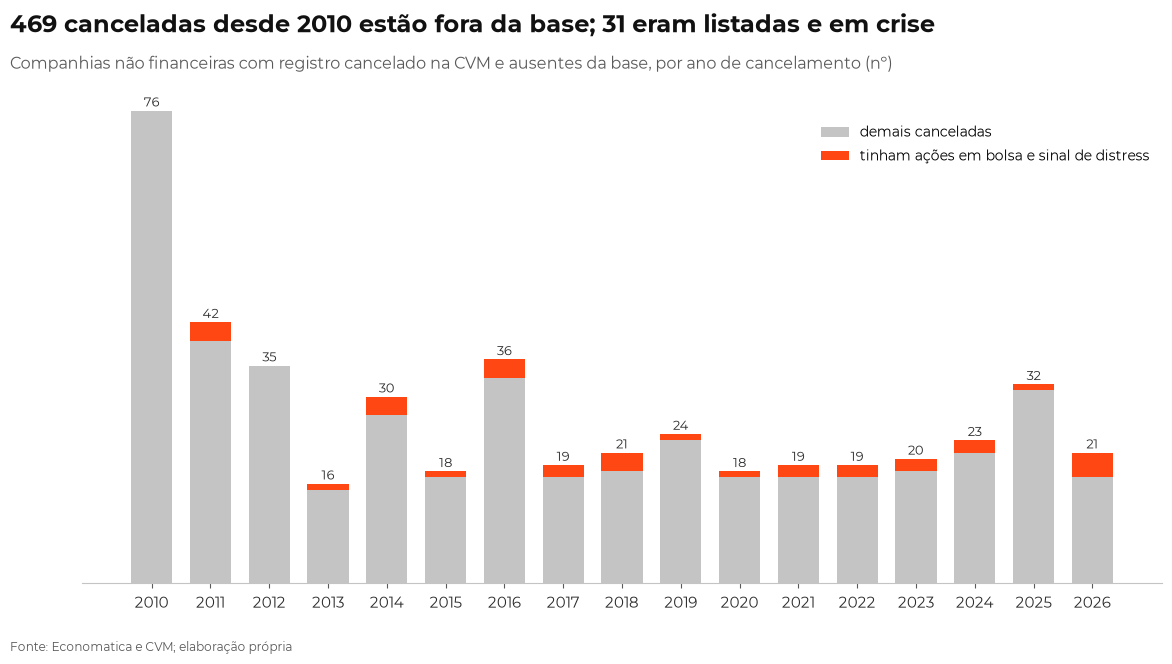

In [5]:
# Gráfico: cancelamentos por ano, destacando as listadas com sinal de distress
grp = canc.assign(grupo=np.where(canc['tinha_acoes_em_bolsa'] & canc['sinal_distress'], 'listada, com sinal de distress', 'demais'))
tab = grp.pivot_table(index='ano_cancel', columns='grupo', values='CNPJ_CIA', aggfunc='count', fill_value=0)
fig, ax = plt.subplots(figsize=cfg.TAMANHO_FIG)
b1 = ax.bar(tab.index, tab['demais'], color=cfg.CINZA, width=0.7, label='demais canceladas')
b2 = ax.bar(tab.index, tab['listada, com sinal de distress'], bottom=tab['demais'], color=cfg.COR_DESTAQUE, width=0.7,
            label='tinham ações em bolsa e sinal de distress')
for x, tot in zip(tab.index, tab.sum(axis=1)):
    ax.annotate(style.num_br(tot), (x, tot), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9, color=cfg.COR_EIXO)
ax.set_xticks(tab.index)
ax.yaxis.set_visible(False); ax.spines['left'].set_visible(False); ax.grid(False)
ax.legend(loc='upper right', fontsize=10)
n_d = int((canc['tinha_acoes_em_bolsa'] & canc['sinal_distress']).sum())
style.titulos(fig, f'{len(canc)} canceladas desde 2010 estão fora da base; {n_d} eram listadas e em crise',
              'Companhias não financeiras com registro cancelado na CVM e ausentes da base, por ano de cancelamento (nº)')
style.salvar(fig, 'fig02_canceladas_fora_da_base')
plt.show()

In [6]:
# As listadas com sinal de distress: são os eventos que o Screening deixou de fora
canc[canc['tinha_acoes_em_bolsa'] & canc['sinal_distress']][['DENOM_SOCIAL', 'DT_CANCEL', 'MOTIVO_CANCEL', 'SETOR_ATIV']]

,DENOM_SOCIAL,DT_CANCEL,MOTIVO_CANCEL,SETOR_ATIV
449,VARIG PARTICIPAÇÕES EM TRANSP AÉREOS S/A,2011-01-04,CANCELAMENTO DE OFÍCIO,Emp. Adm. Part. - Serviços Transporte e Logística
450,VARIG PARTIC. EM SERVIÇOS COMPLEMENTARES,2011-01-04,CANCELAMENTO DE OFÍCIO,Emp. Adm. Part. - Serviços Transporte e Logística
16,VBC ENERGIA SA,2011-11-07,CANCELAMENTO DE OFÍCIO,Emp. Adm. Part. - Energia Elétrica
1785,MARAMBAIA ENERGIA RENOVÁVEL SA,2013-01-07,CANCELAMENTO DE OFÍCIO,"Agricultura (Açúcar, Álcool e Cana)"
2268,WIEST SA,2014-01-09,CANCELAMENTO DE OFÍCIO,Metalurgia e Siderurgia
1474,SERGEN SERVS GERAIS DE ENG SA,2014-07-30,CANCELAMENTO DE OFÍCIO,"Construção Civil, Mat. Constr. e Decoração"
1290,CLARION S/A AGROINDUSTRIAL,2014-12-18,CANCELAMENTO DE OFÍCIO,"Agricultura (Açúcar, Álcool e Cana)"
1539,HOTEIS E TURISMO GUANABARA SA,2015-03-13,CANCELAMENTO DE OFÍCIO,Hospedagem e Turismo
2338,METALURGICA DUQUE SA - EM RECUPERAÇÃO JUDICIAL,2016-01-07,CANCELAMENTO DE OFÍCIO,Metalurgia e Siderurgia
2304,MASSA FALIDA DA FÁBRICA DE TECIDOS CARLOS RENA...,2016-01-07,CANCELAMENTO DE OFÍCIO,Têxtil e Vestuário


**Leitura.** A lista completa está em `data/processed/canceladas_fora_da_base.csv`. Entre as listadas com sinal de distress estão casos clássicos de crise: Varig, MMX (massa falida), Hopi Hari, Buettner, Coteminas e Springs Global (as duas em recuperação judicial, canceladas de ofício em 2026). Nenhum desses casos pode virar evento na nossa base, porque eles não estão nela. As 31 são um **limite inferior**: muitos cancelamentos "voluntários" e incorporações também acontecem depois de anos de crise.

### 1c. Entradas no painel: a onda de IPOs

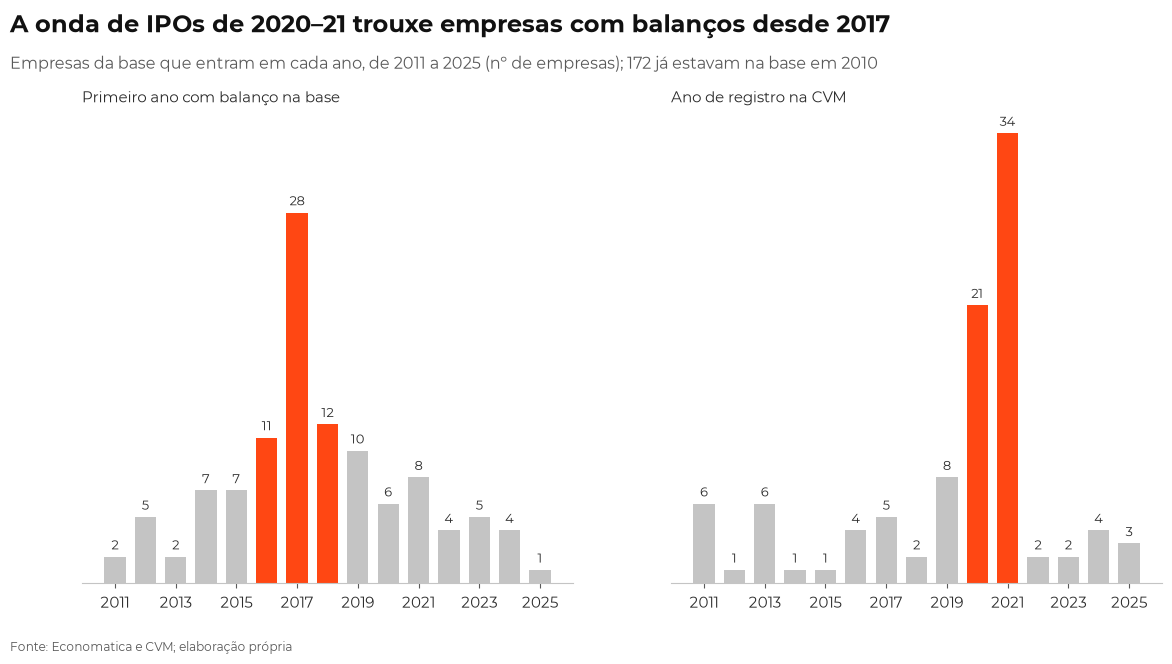

In [7]:
primeiro = ea.groupby('ticker').agg(primeiro_ano=('ano', 'min'), ano_registro=('ano_registro', 'first'))
entradas = primeiro['primeiro_ano'].value_counts().sort_index().loc[2011:]
registros = primeiro['ano_registro'].dropna().astype(int).value_counts().sort_index().loc[2011:2025]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=cfg.TAMANHO_FIG, sharey=True)
for ax, serie, titulo, dest in [(ax1, entradas, 'Primeiro ano com balanço na base', (2016, 2017, 2018)),
                                (ax2, registros, 'Ano de registro na CVM', (2020, 2021))]:
    serie = serie.reindex(range(2011, 2026), fill_value=0)
    cores = [cfg.COR_DESTAQUE if a in dest else cfg.CINZA for a in serie.index]
    b = ax.bar(serie.index, serie.values, color=cores, width=0.7)
    style.rotular_barras(ax, b)
    ax.set_xticks(serie.index[::2]); ax.yaxis.set_visible(False); ax.spines['left'].set_visible(False); ax.grid(False)
    ax.set_title(titulo, fontsize=11, color=cfg.COR_EIXO, loc='left')
style.titulos(fig, 'A onda de IPOs de 2020–21 trouxe empresas com balanços desde 2017',
              'Empresas da base que entram em cada ano, de 2011 a 2025 (nº de empresas); 172 já estavam na base em 2010')
style.salvar(fig, 'fig03_entradas_ipos')
plt.show()

**Leitura.** Pelo **ano de registro na CVM** (direita), a onda de IPOs de 2020–21 aparece com clareza. Pelo **primeiro ano na base** (esquerda), as entradas se concentram em 2016–2018, porque as empresas que abriram capital em 2020–21 trazem no prospecto as demonstrações dos três anos anteriores. Isso tem duas consequências:
- parte do treino (t ≤ 2018) é formada por empresas que **ainda não eram abertas** (flag `pre_registro`);
- todas elas **sobreviveram** até o IPO e até hoje, o que reforça o viés de sobrevivência no treino.

### 1d. Perfil do treino × validação × teste (amostra em risco)

In [8]:
perfil = risco.groupby('split').agg(
    empresa_anos=('ticker', 'size'), empresas=('ticker', 'nunique'),
    idade_registro_media=('idade_registro', 'mean'),
    ativo_mediano_R_bi=('ativo_total', lambda s: s.median() / 1e6),
    log_ativo_medio=('log_ativo', 'mean'),
    alavancagem_media=('alavancagem_w', 'mean'),
    pct_pre_registro=('pre_registro', 'mean'),
    taxa_eventos=('Y', 'mean'),
).reindex(['treino', 'validacao', 'teste'])
perfil.style.format({'pct_pre_registro': lambda x: style.pct_br(x, 1), 'taxa_eventos': lambda x: style.pct_br(x, 1),
                     'empresa_anos': '{:.0f}', 'empresas': '{:.0f}'} |
                    {c: lambda x: style.num_br(x, 2) for c in ['idade_registro_media', 'ativo_mediano_R_bi', 'log_ativo_medio', 'alavancagem_media']})

,empresa_anos,empresas,idade_registro_media,ativo_mediano_R_bi,log_ativo_medio,alavancagem_media,pct_pre_registro,taxa_eventos
split,,,,,,,,
treino,957,208,"18,32","3,47","14,90","0,28","8,9%","12,7%"
validacao,276,168,"19,35","4,34","15,09","0,29","13,0%","7,6%"
teste,475,196,"22,05","4,94","15,44","0,29","1,1%","11,4%"


**Leitura.** A alavancagem média quase não muda entre os períodos (cerca de 0,28). O teste tem empresas **maiores** (ativo mediano de R$ 4,9 bi contra R$ 3,5 bi no treino) e registradas há mais tempo. O treino tem 9% de anos pré-registro, e o teste, 1%. As diferenças são moderadas, mas o modelo vai ser avaliado numa população um pouco diferente daquela em que foi treinado.

### 1e. Conclusão sobre o viés de sobrevivência

- **Tamanho:** a base cobre **47%** das companhias não financeiras com ações em bolsa em 2010 e **73%** em 2025. Nenhuma das 469 companhias não financeiras canceladas desde 2010 está na base. Pelo menos **31** delas eram listadas e tinham sinais explícitos de crise (recuperação judicial, falência, liquidação ou cancelamento de ofício).
- **Direção:** as empresas excluídas são, desproporcionalmente, as que entraram em distress. Então:
  1. **a taxa de eventos está subestimada**, principalmente no treino (os primeiros anos), que é onde a cobertura é menor;
  2. **o treino é mais "saudável" que a realidade**: o modelo vê poucas trajetórias que terminam mal;
  3. **as associações estimadas tendem a ser conservadoras** (atenuadas). As empresas de pior perfil que quebraram de fato estão fora, então a diferença entre "perfil ruim" e "perfil bom" fica menor do que é. Se mesmo assim encontrarmos associação, ela provavelmente é real.
- **O que não podemos afirmar:** a taxa de eventos absoluta e a calibração do modelo para a população inteira de companhias abertas. Probabilidades previstas devem ser lidas como **risco relativo**, não como probabilidade de default.
- **Como mitigar na Fase 4:** (i) robustez com o painel balanceado (empresas presentes desde 2010); (ii) robustez sem os anos pré-registro; (iii) se possível, reexportar do Economatica incluindo as **canceladas** (o Screening permite incluir ativos cancelados), o que resolveria o problema na origem.

## 2. Variável de interesse: entrada em distress

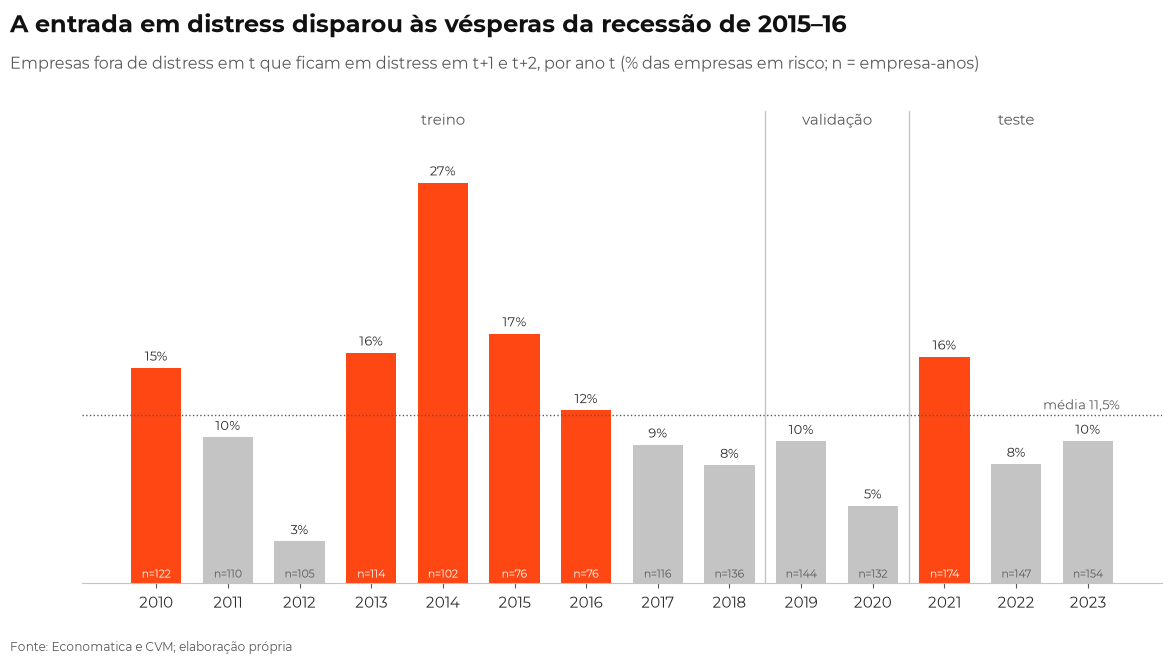

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
taxa,"0,148","0,100","0,029","0,158","0,275","0,171","0,118","0,095","0,081","0,097","0,053","0,155","0,082","0,097"
n,"122,000","110,000","105,000","114,000","102,000","76,000","76,000","116,000","136,000","144,000","132,000","174,000","147,000","154,000"
eventos,"18,000","11,000","3,000","18,000","28,000","13,000","9,000","11,000","11,000","14,000","7,000","27,000","12,000","15,000"


In [9]:
por_ano = risco.groupby('ano')['Y'].agg(taxa='mean', n='size', eventos='sum')
media = risco['Y'].mean()
fig, ax = eda.fig_barras_ano(por_ano['taxa'], destaque=list(por_ano.index[por_ano['taxa'] > media]), pct=True, casas=0)
for x, n in zip(por_ano.index, por_ano['n']):
    ax.annotate(f'n={n}', (x, 0), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8, color='white' if por_ano.loc[x, 'taxa'] > media else cfg.COR_SUBTITULO)
ax.axhline(media, color=cfg.COR_SUBTITULO, lw=1, ls=':')
topo = por_ano['taxa'].max() * 1.18
ax.set_ylim(0, topo)
ax.annotate(f'média {style.pct_br(media)}', (por_ano.index[-1] + 0.45, media), xytext=(0, 4), textcoords='offset points',
            ha='right', fontsize=9, color=cfg.COR_SUBTITULO)
for a, (lo, hi) in cfg.SPLITS.items():
    ax.annotate(a.replace('validacao', 'validação'), ((lo + hi) / 2, topo), ha='center', va='top', fontsize=10.5, color=cfg.COR_SUBTITULO)
    if lo > cfg.ANO_INI:
        ax.axvline(lo - 0.5, color=cfg.CINZA, lw=1)
style.titulos(fig, 'A entrada em distress disparou às vésperas da recessão de 2015–16',
              'Empresas fora de distress em t que ficam em distress em t+1 e t+2, por ano t (% das empresas em risco; n = empresa-anos)')
style.salvar(fig, 'fig04_taxa_eventos_ano')
plt.show()
por_ano.T

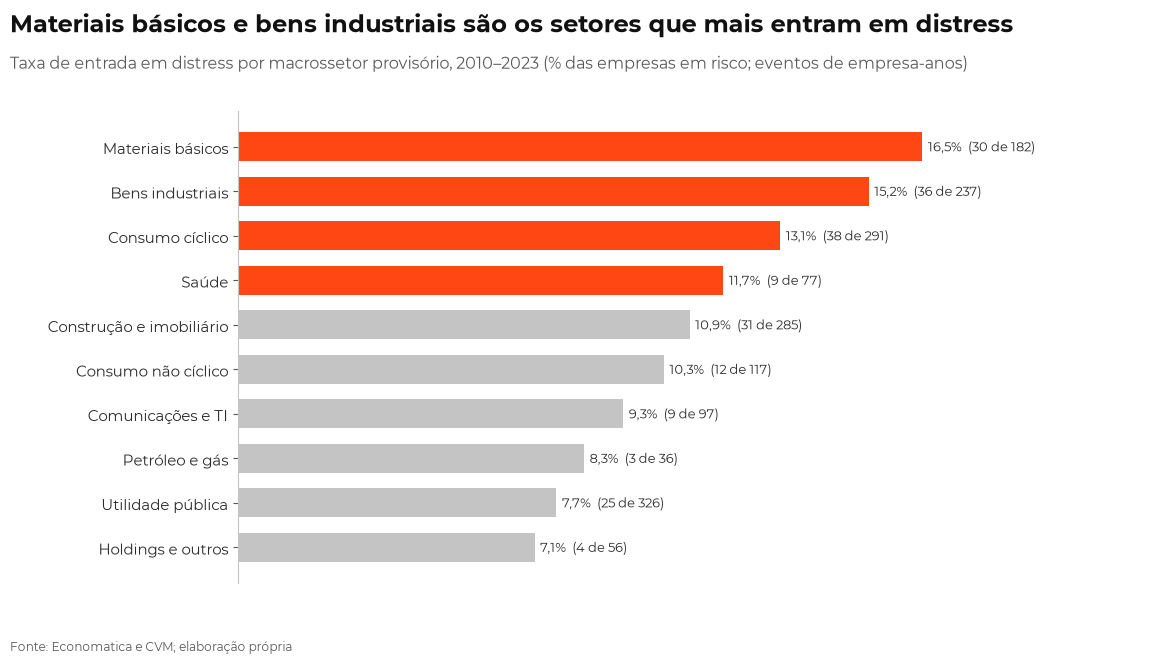

In [10]:
por_setor = risco.groupby('setor')['Y'].agg(taxa='mean', n='size', eventos='sum').sort_values('taxa')
por_setor = por_setor[por_setor['n'] >= 20]   # 'Sem classificação' tem só 4 obs.
fig, ax = plt.subplots(figsize=cfg.TAMANHO_FIG)
cores = [cfg.COR_DESTAQUE if t > media else cfg.CINZA for t in por_setor['taxa']]
b = ax.barh(por_setor.index, por_setor['taxa'], color=cores, height=0.65)
for bar, (t, n, e) in zip(b, por_setor[['taxa', 'n', 'eventos']].values):
    ax.annotate(f'{style.pct_br(t)}  ({int(e)} de {int(n)})', (t, bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9.5, color=cfg.COR_EIXO)
ax.xaxis.set_visible(False); ax.spines['bottom'].set_visible(False); ax.grid(False)
ax.set_xlim(0, por_setor['taxa'].max() * 1.35)
style.titulos(fig, 'Materiais básicos e bens industriais são os setores que mais entram em distress',
              'Taxa de entrada em distress por macrossetor provisório, 2010–2023 (% das empresas em risco; eventos de empresa-anos)')
fig.subplots_adjust(left=0.2)
style.salvar(fig, 'fig05_taxa_eventos_setor')
plt.show()

**Leitura.**
- **Desbalanceamento:** 197 eventos em 1.708 empresa-anos (11,5%), ou seja, cerca de 1 evento para cada 8 casos. Não é extremo, mas a acurácia sozinha engana: prever sempre "não" acerta 88%. Por isso a métrica principal na Fase 4 é a AUC-PR.
- **Tempo:** a taxa varia muito, de 3% (2012) a 28% (2014). O pico em t = 2014 corresponde a empresas que entraram em distress em 2015 e 2016, os anos da recessão. Em 2021 há outro salto, com a alta da Selic de 2022–23. O ano entra como controle.
- **Setor:** as diferenças são moderadas, de 7% (utilidade pública, com receita regulada) a 17% (materiais básicos, cíclicos e expostos a commodities). O agrupamento é provisório (Subsetor Bovespa pendente).
- **Poucos eventos por ano:** alguns anos têm menos de 10 eventos, e alguns setores, menos de 10. Dummies de ano e de setor juntas no mesmo modelo vão consumir muitos graus de liberdade.

## 3. Dados faltantes

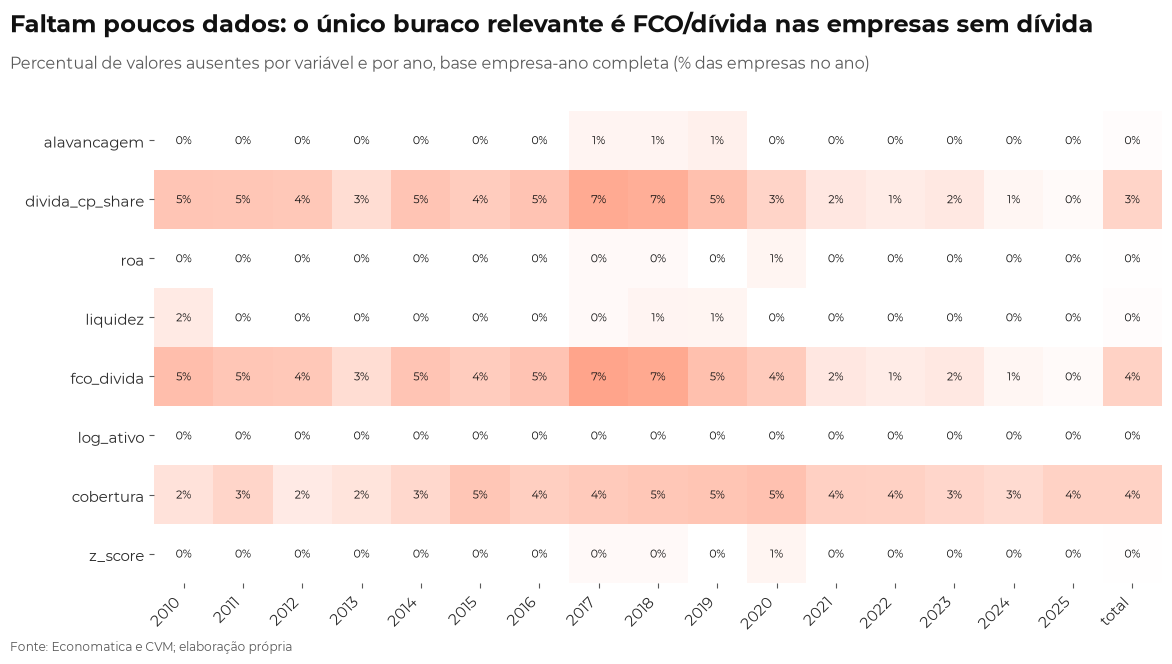

In [11]:
vars_nan = list(cfg.EXPLICATIVAS) + ['cobertura', 'z_score']
nan_ano = ea.groupby('ano')[vars_nan].apply(lambda g: g.isna().mean()).T
nan_ano['total'] = ea[vars_nan].isna().mean()
fig, ax = eda.fig_heatmap(nan_ano, style.CMAP_SEQ, vmin=0, vmax=max(0.15, nan_ano.values.max()), casas=0, pct=True, fontsize=8)
style.titulos(fig, 'Faltam poucos dados: o único buraco relevante é FCO/dívida nas empresas sem dívida',
              'Percentual de valores ausentes por variável e por ano, base empresa-ano completa (% das empresas no ano)')
fig.subplots_adjust(left=0.13)
style.salvar(fig, 'fig06_faltantes')
plt.show()

**Leitura.** Depois de ficar com o 4T e com as linhas que têm balanço, quase não sobram faltantes. As exceções:
- `fco_divida` e `divida_cp_share`: NaN quando a empresa **não tem dívida**, que é um NaN estrutural e não um dado perdido. A flag `sem_divida` guarda essa informação, e no treino a taxa de eventos das empresas sem dívida é de 16% (44 casos).
- `cobertura`: NaN quando a despesa financeira é menor ou igual a zero.
- Não há padrão temporal forte.

Na Fase 4, a regressão logística vai precisar de uma regra para os sem dívida. Sugestão: imputar `fco_divida` pelo percentil 99 do treino (capacidade de pagamento "infinita") e `divida_cp_share` por 0, mantendo a flag `sem_divida`. **Decisão pendente.**

## 4. Distribuições antes e depois da winsorização

Limites nos percentis 1% e 99% **do treino**, aplicados a todas as linhas. Eixo em escala *symlog* (linear perto de zero, logarítmica nas caudas) para que os extremos caibam no gráfico.

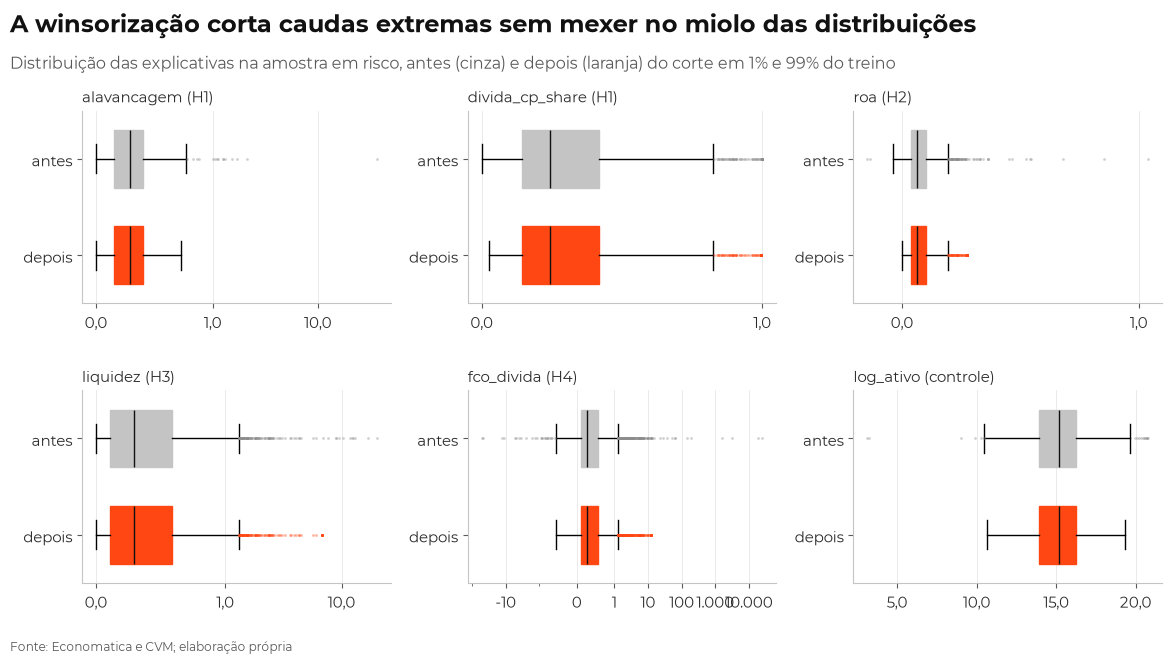

In [12]:
fig, axes = plt.subplots(2, 3, figsize=cfg.TAMANHO_FIG)
for ax, (v, (h, s, desc)) in zip(axes.flat, cfg.EXPLICATIVAS.items()):
    dados_bp = [risco[f'{v}_w'].dropna(), risco[v].dropna()]
    bp = ax.boxplot(dados_bp, orientation='horizontal', widths=0.6, patch_artist=True, tick_labels=['depois', 'antes'],
                    flierprops=dict(marker='o', ms=2, alpha=0.4, markeredgecolor='none'),
                    medianprops=dict(color=cfg.COR_TITULO))
    for patch, cor in zip(bp['boxes'], [cfg.COR_DESTAQUE, cfg.CINZA]):
        patch.set_facecolor(cor); patch.set_edgecolor(cor)
    for fl, cor in zip(bp['fliers'], [cfg.COR_DESTAQUE, '#8C8C8C']):
        fl.set_markerfacecolor(cor)
    if v != 'log_ativo':
        ax.set_xscale('symlog', linthresh=1)
    if v == 'fco_divida':
        ax.set_xticks([-10, 0, 1, 10, 100, 1000, 10000])
        ax.xaxis.set_major_formatter(style.formatador(0))
    else:
        ax.xaxis.set_major_formatter(style.formatador(1))
    ax.set_title(f'{v} ({h})', fontsize=10.5, color=cfg.COR_EIXO, loc='left')
    ax.grid(axis='y', visible=False)
style.titulos(fig, 'A winsorização corta caudas extremas sem mexer no miolo das distribuições',
              'Distribuição das explicativas na amostra em risco, antes (cinza) e depois (laranja) do corte em 1% e 99% do treino')
fig.subplots_adjust(hspace=0.45, wspace=0.25)
style.salvar(fig, 'fig07_winsorizacao')
plt.show()

In [13]:
q = [0.01, 0.25, 0.5, 0.75, 0.99]
antes = risco[list(cfg.EXPLICATIVAS)].quantile(q).T.add_prefix('antes p')
depois = risco[[f'{v}_w' for v in cfg.EXPLICATIVAS]].quantile(q).T.add_prefix('depois p')
depois.index = antes.index
pd.concat([antes[['antes p0.01', 'antes p0.99']], depois[['depois p0.01', 'depois p0.99']],
           risco[list(cfg.EXPLICATIVAS)].agg(['min', 'max']).T], axis=1)

,antes p0.01,antes p0.99,depois p0.01,depois p0.99,min,max
alavancagem,"0,000","0,749","0,000","0,730","0,000","36,163"
divida_cp_share,"0,017","1,000","0,026","0,996","0,000","1,000"
roa,"0,000","0,303","0,000","0,272","-0,146","1,104"
liquidez,"0,002","4,078","0,003","4,078","0,000","19,999"
fco_divida,"-0,829","12,242","-0,560","12,060","-51,561","24.720,000"
log_ativo,"10,916","19,051","10,916","19,051","3,133","20,773"


**Leitura.** Os extremos que a winsorização remove são casos reais, mas fora da escala da maioria das empresas:
- alavancagem de até 36: dívida 36 vezes o ativo, com PL muito negativo;
- `fco_divida` de até 24.720: empresa com dívida quase nula;
- liquidez de até 20.

Numa logística, esses pontos teriam alavancagem enorme. A mediana e os quartis não mudam.

## 5. Cada explicativa × alvo (treino)

Para cada variável, dividimos o **treino** em quintis e calculamos a taxa de entrada em distress em cada quintil. O padrão "confirma" a hipótese quando a diferença entre o Q5 e o Q1 tem o sinal esperado e é maior que 3 p.p. A barra mais alta aparece em laranja.

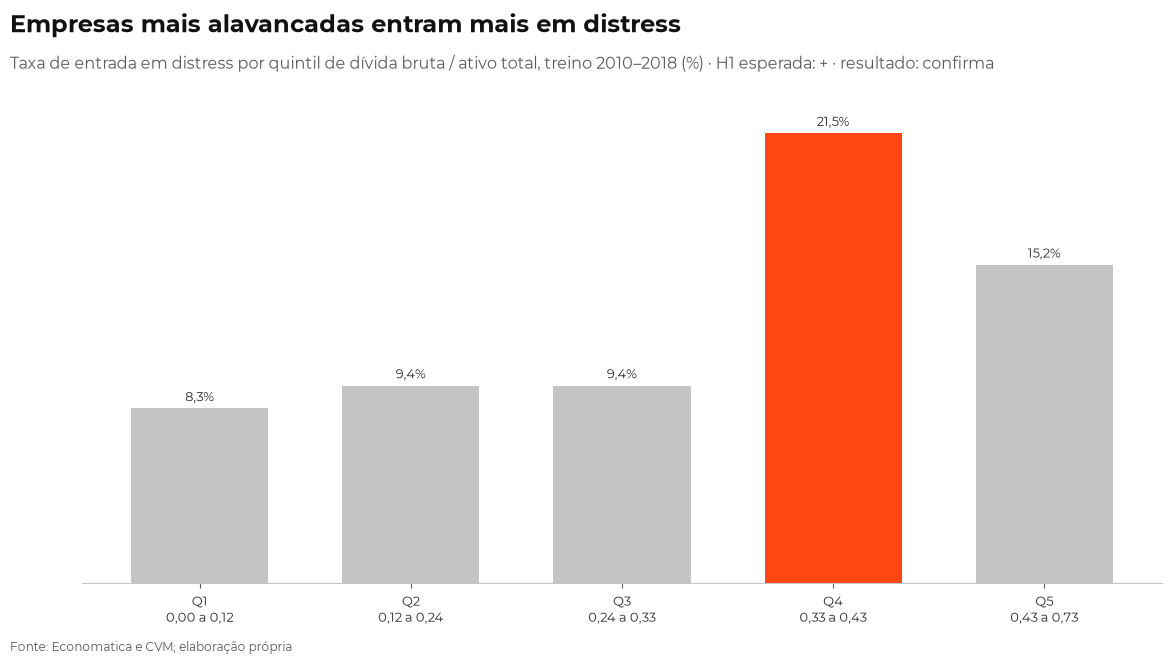

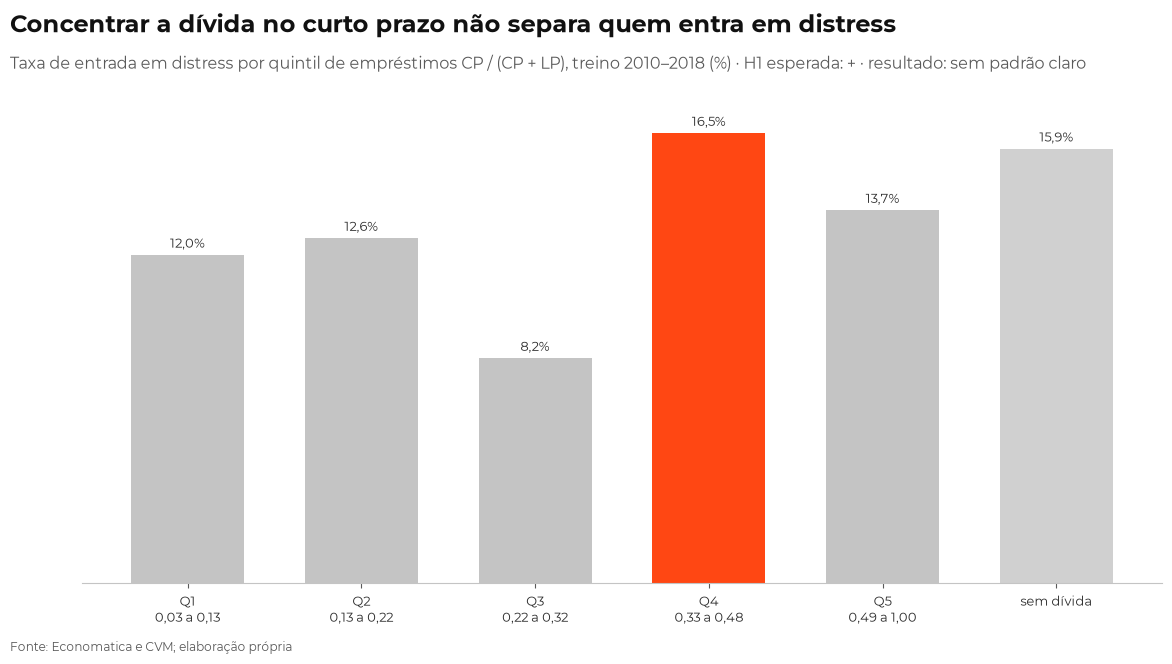

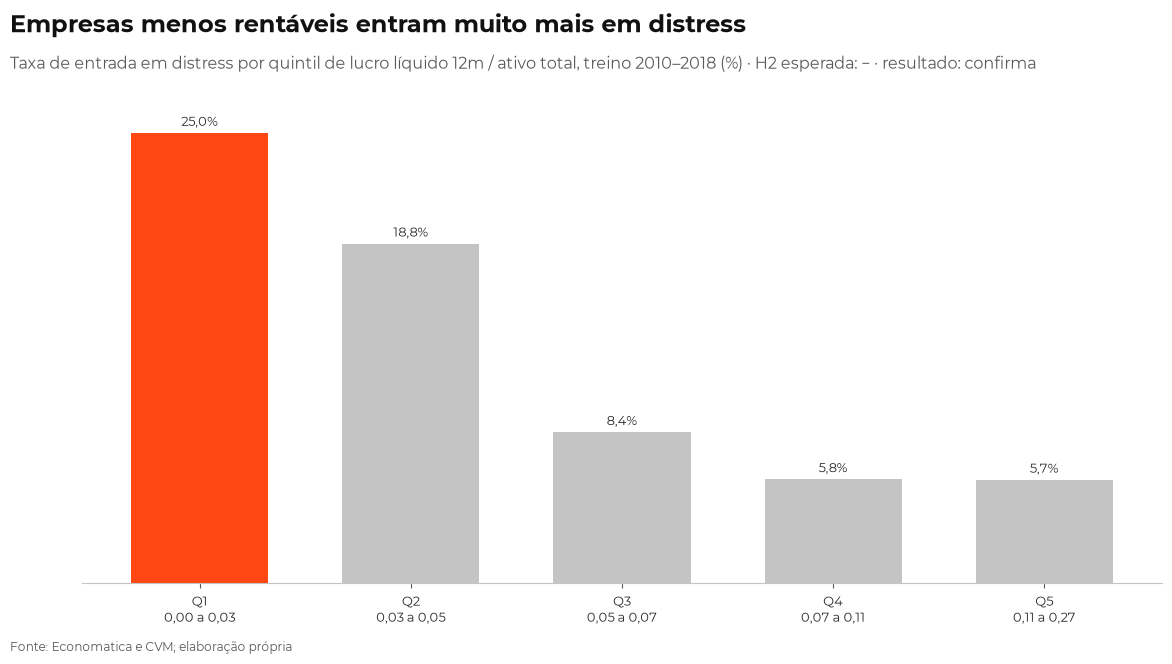

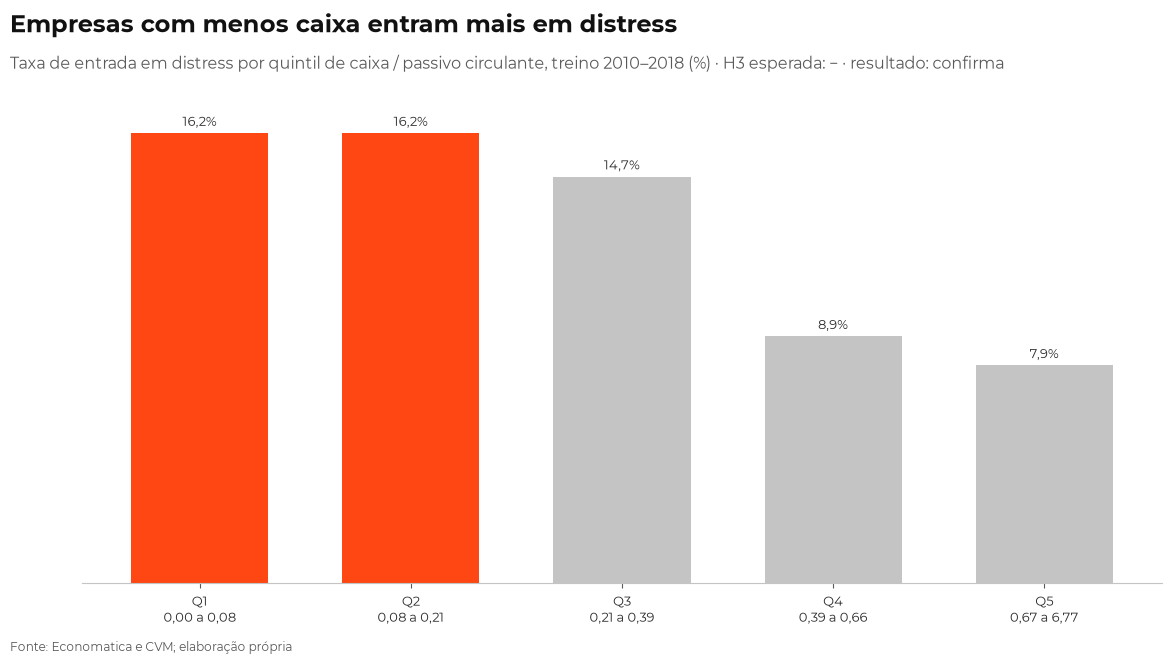

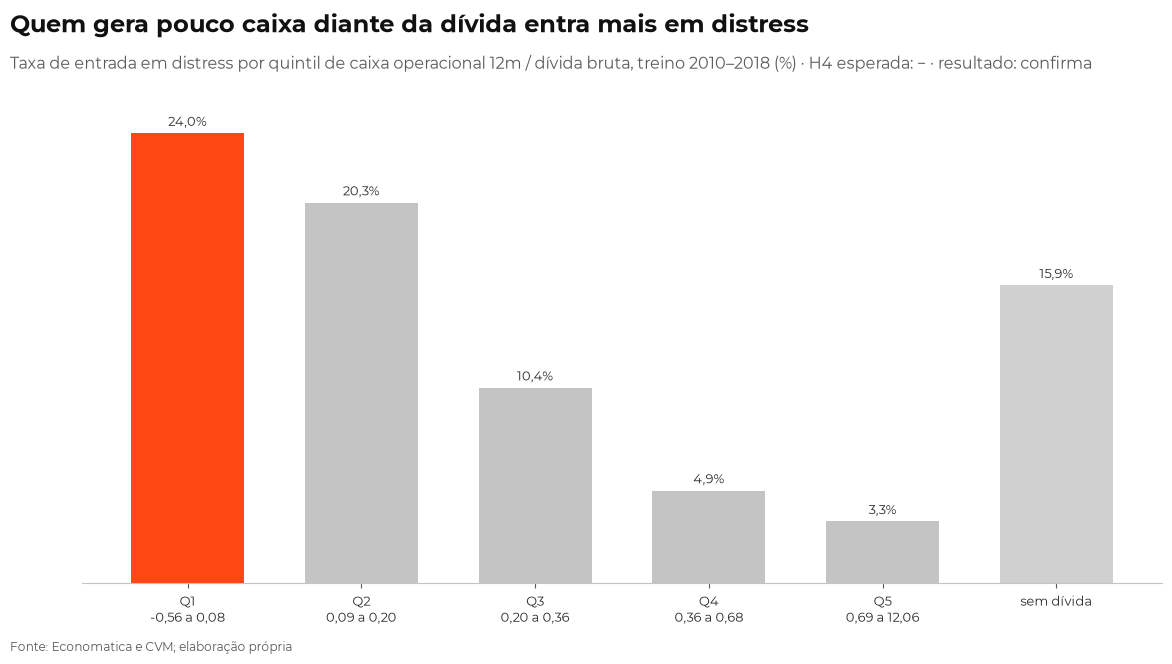

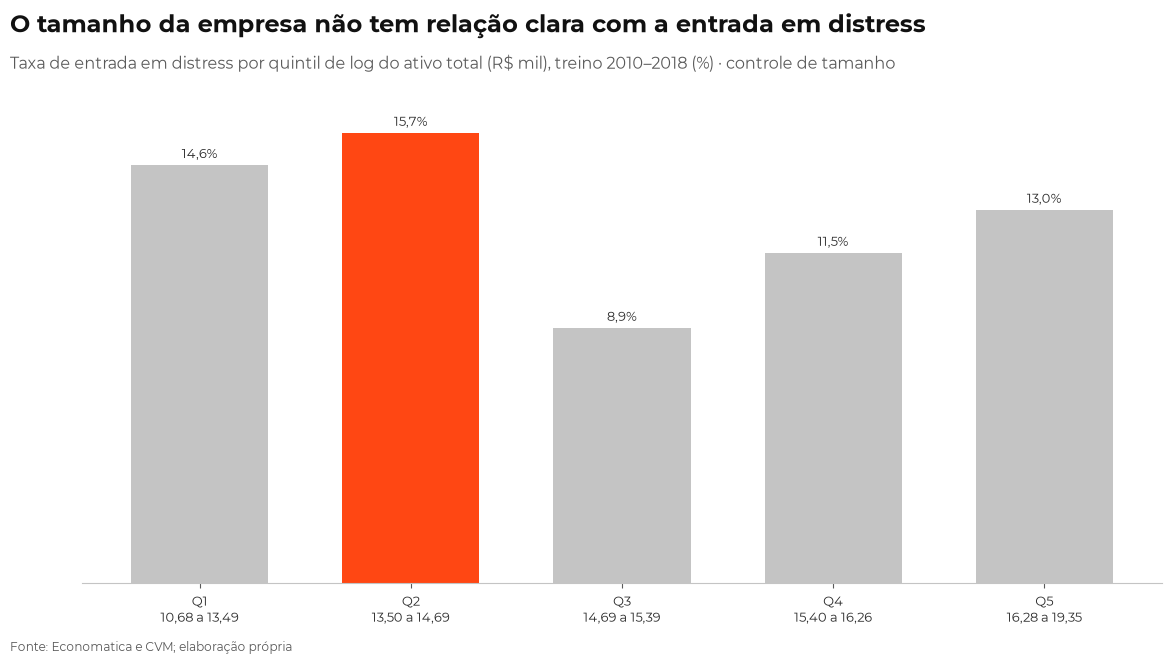

,hipótese,Q1,Q5,Q5 − Q1 (p.p.),resultado
variável,,,,,
alavancagem,H1 (+),"8,3%","15,2%","6,8",confirma
divida_cp_share,H1 (+),"12,0%","13,7%","1,6",sem padrão claro
roa,H2 (−),"25,0%","5,7%","-19,3",confirma
liquidez,H3 (−),"16,2%","7,9%","-8,4",confirma
fco_divida,H4 (−),"24,0%","3,3%","-20,7",confirma
log_ativo,controle,"14,6%","13,0%","-1,6",controle


In [14]:
titulos_h = {
    'alavancagem': 'Empresas mais alavancadas entram mais em distress',
    'divida_cp_share': 'Concentrar a dívida no curto prazo não separa quem entra em distress',
    'roa': 'Empresas menos rentáveis entram muito mais em distress',
    'liquidez': 'Empresas com menos caixa entram mais em distress',
    'fco_divida': 'Quem gera pouco caixa diante da dívida entra mais em distress',
    'log_ativo': 'O tamanho da empresa não tem relação clara com a entrada em distress',
}
resumo = []
for i, (v, (h, s, desc)) in enumerate(cfg.EXPLICATIVAS.items(), start=8):
    tab = eda.taxa_por_quintil(treino, f'{v}_w')
    extra = None
    if v in ('fco_divida', 'divida_cp_share'):
        sd = treino[treino['sem_divida']]
        extra = ('sem dívida', sd['Y'].mean())
    ver, dif = eda.veredito(tab, s) if s else ('controle', tab['taxa'].iloc[-1] - tab['taxa'].iloc[0])
    resumo.append({'variável': v, 'hipótese': f'{h} ({s})' if s else h, 'Q1': tab['taxa'].iloc[0], 'Q5': tab['taxa'].iloc[-1],
                   'Q5 − Q1 (p.p.)': 100 * dif, 'resultado': ver})
    fig, ax = eda.fig_quintil(tab, extra)
    rot = [f'{q}\n{style.num_br(a, 2)} a {style.num_br(b, 2)}' for q, a, b in zip(tab.index, tab['de'], tab['ate'])]
    ax.set_xticks(range(len(rot) + (extra is not None)), rot + ([extra[0]] if extra else []), fontsize=9.5)
    sub = (f'Taxa de entrada em distress por quintil de {desc}, treino 2010–2018 (%) · '
           + (f'{h} esperada: {s} · resultado: {ver}' if s else 'controle de tamanho'))
    style.titulos(fig, titulos_h[v], sub)
    style.salvar(fig, f'fig{i:02d}_quintil_{v}')
    plt.show()
resumo = pd.DataFrame(resumo).set_index('variável')
resumo.style.format({'Q1': lambda x: style.pct_br(x, 1), 'Q5': lambda x: style.pct_br(x, 1), 'Q5 − Q1 (p.p.)': lambda x: style.num_br(x, 1)})

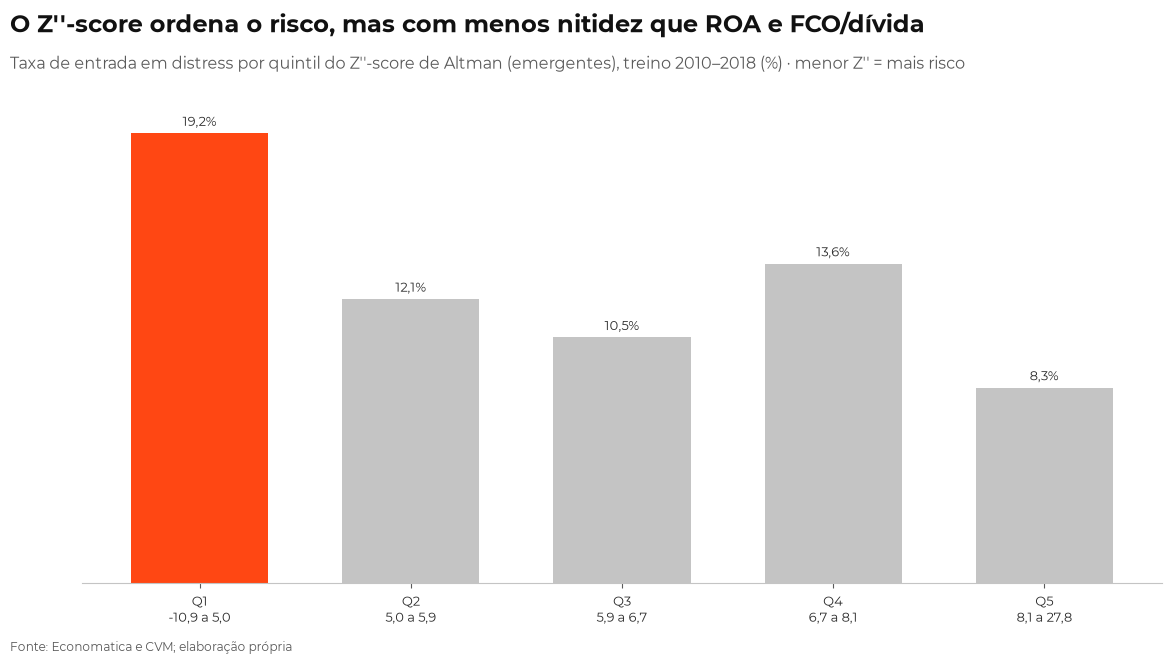

,taxa,n,eventos,de,ate
quintil,,,,,
Q1,"0,192",193,"37,000","-10,860","5,012"
Q2,"0,121",190,"23,000","5,016","5,941"
Q3,"0,105",191,"20,000","5,942","6,726"
Q4,"0,136",191,"26,000","6,727","8,073"
Q5,"0,083",192,"16,000","8,082","27,826"


In [15]:
# Referência: o Z''-score (baseline) também ordena o risco?
tab_z = eda.taxa_por_quintil(treino, 'z_score')
fig, ax = eda.fig_quintil(tab_z)
rot = [f'{q}\n{style.num_br(a, 1)} a {style.num_br(b, 1)}' for q, a, b in zip(tab_z.index, tab_z['de'], tab_z['ate'])]
ax.set_xticks(range(len(rot)), rot, fontsize=9.5)
style.titulos(fig, "O Z''-score ordena o risco, mas com menos nitidez que ROA e FCO/dívida",
              "Taxa de entrada em distress por quintil do Z''-score de Altman (emergentes), treino 2010–2018 (%) · menor Z'' = mais risco")
style.salvar(fig, 'fig14_quintil_zscore')
plt.show()
tab_z

**Leitura das hipóteses (treino):**
- **H2, ROA (−): confirma, e é o padrão mais forte.** A taxa cai de 25% no quintil menos rentável para 6% no mais rentável, de forma monotônica.
- **H4, FCO/dívida (−): confirma, também forte e monotônico**, de 24% para 3%. As empresas **sem dívida** (16%) não são as mais seguras, o que é contraintuitivo. Uma explicação possível: empresas sem dívida e com despesa financeira (arrendamentos, variação cambial) têm cobertura instável.
- **H3, liquidez (−): confirma**, de cerca de 16% nos quintis de pouco caixa para 8% nos de muito caixa.
- **H1, alavancagem (+): confirma, mas não de forma linear.** Os três primeiros quintis ficam em cerca de 9%, e o salto acontece no Q4 (21%). O Q5 (15%) fica abaixo do Q4, um padrão de **limiar** e não linear.
- **H1, dívida de curto prazo (+): sem padrão claro.** As taxas oscilam entre 8% e 16% sem tendência.
- **Tamanho:** a relação tem formato de U fraco, sem tendência.
- **Z'':** ordena o risco (19% no Q1 contra 8% no Q5), mas não de forma monotônica (o Q4 sobe). É uma baseline razoável, e as variáveis ROA e FCO/dívida, sozinhas, já separam melhor.

## 6. Correlação entre os índices e VIF (treino)

Usamos **Spearman** (correlação de postos), porque é robusta a caudas e a relações não lineares. A correlação é calculada **entre os índices**, e não entre valores em R$: em R$, tudo se correlaciona com o tamanho da empresa.

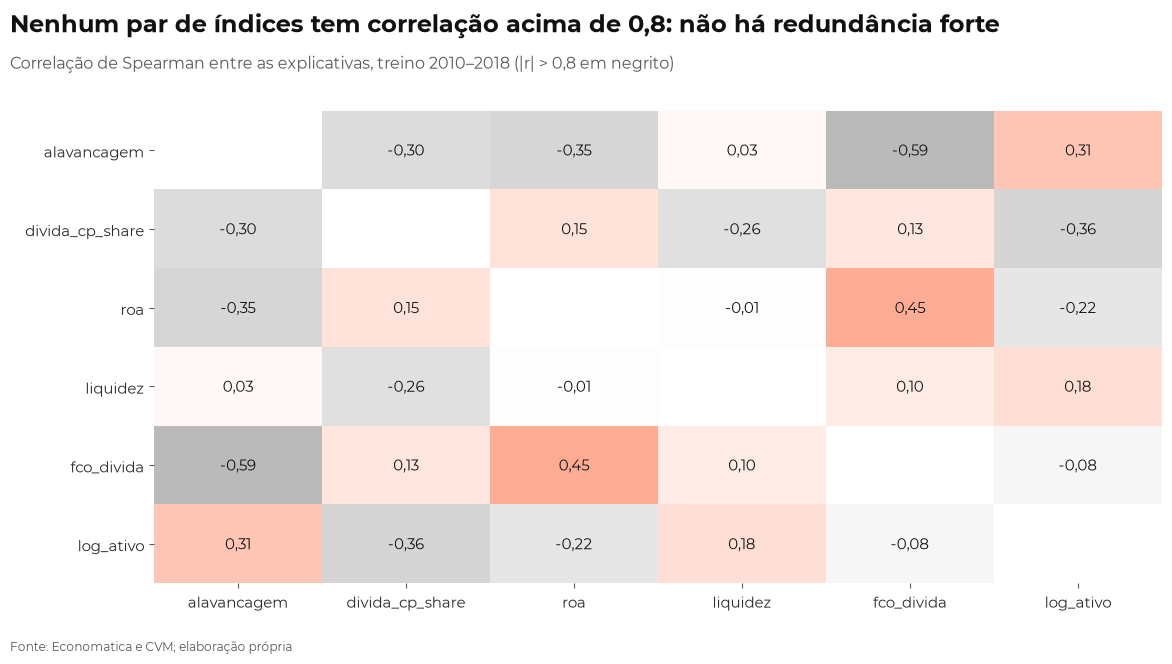

Pares com |r| > 0,8: nenhum


In [16]:
cols_w = [f'{v}_w' for v in cfg.EXPLICATIVAS]
rho = treino[cols_w].corr(method='spearman')
rho.index = rho.columns = list(cfg.EXPLICATIVAS)
alto = (rho.abs() > 0.8) & ~np.eye(len(rho), dtype=bool)
rho_plot = rho.mask(np.eye(len(rho), dtype=bool))   # diagonal (=1) em branco
fig, ax = eda.fig_heatmap(rho_plot, style.CMAP_DIV, vmin=-1, vmax=1, casas=2, destaque=alto, fontsize=11)
n_alto = int(alto.values.sum() / 2)
style.titulos(fig, 'Nenhum par de índices tem correlação acima de 0,8: não há redundância forte' if n_alto == 0
              else f'{n_alto} par(es) de índices com correlação acima de 0,8',
              'Correlação de Spearman entre as explicativas, treino 2010–2018 (|r| > 0,8 em negrito)')
fig.subplots_adjust(left=0.13)
style.salvar(fig, 'fig15_correlacao_spearman')
plt.show()
print('Pares com |r| > 0,8:', [(a, b) for a in rho for b in rho if a < b and alto.loc[a, b]] or 'nenhum')

In [17]:
v = eda.vif(treino, cols_w)
v.index = list(cfg.EXPLICATIVAS)
v.to_frame()

,VIF
alavancagem,"1,420"
divida_cp_share,"1,357"
roa,"1,249"
liquidez,"1,139"
fco_divida,"1,454"
log_ativo,"1,235"


**Leitura.**
- A maior correlação é entre **alavancagem e FCO/dívida (−0,59)**. Faz sentido, porque a dívida está no denominador de uma e no numerador da outra. Ainda assim, cada uma traz informação própria.
- ROA e FCO/dívida têm correlação de 0,45, já que ambos medem desempenho.
- Todos os **VIF ficam abaixo de 1,5**, muito longe dos limites usuais de 5 ou 10. **Não há multicolinearidade** que obrigue a tirar variáveis.

## 7. Decisão de modelagem (proposta para a dupla aprovar)

**Variáveis que seguem para a Fase 4 (todas winsorizadas):**

| variável | hipótese | por que segue |
|---|---|---|
| `roa_w` | H2 (−) | padrão mais forte e monotônico |
| `fco_divida_w` + `sem_divida` | H4 (−) | forte e monotônico; a flag captura os sem dívida |
| `liquidez_w` | H3 (−) | confirma |
| `alavancagem_w` | H1 (+) | confirma, com cara de limiar (ver não linearidade) |
| `divida_cp_share_w` | H1 (+) | sem padrão bivariado, mas **fica**: é a hipótese a ser testada, e o efeito pode aparecer controlando pelas outras |
| `log_ativo_w` | controle | |
| ano e setor | controles | setor provisório até chegar o Subsetor Bovespa |

**Nenhuma variável sai por redundância** (nenhum |r| > 0,8, todos os VIF < 1,5).

**O que a exploração sugere para a modelagem:**
1. **Desbalanceamento moderado** (11,5% de eventos): usar `class_weight`, ou equivalente, e avaliar por **AUC-PR**, recall e Brier, nunca por acurácia.
2. **Não linearidades:** a alavancagem tem um salto no Q4, e o tamanho tem formato de U. Na logística, testar *splines* ou faixas; o XGBoost captura isso naturalmente. Comparar a importância das variáveis do XGBoost com os coeficientes da logística vai mostrar onde a linearidade falha.
3. **Ano:** a taxa de eventos varia de 3% a 28%, então o ciclo econômico pesa muito. Dummies de ano funcionam no treino, mas **não existem para os anos do teste**. Alternativas: uma variável macro (Selic, crescimento do PIB) no lugar do ano, ou nenhum controle de ano e aceitar que o modelo mede risco relativo dentro de cada ano. **Decisão pendente.**
4. **Viés de sobrevivência:** ler os coeficientes como provavelmente **atenuados** e as probabilidades como **risco relativo**. Fazer as robustezes com o painel balanceado e sem os anos pré-registro.
5. **Sem dívida:** escolher a regra de imputação de `fco_divida` e `divida_cp_share` (seção 3). **Decisão pendente.**